In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras import layers, models
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


In [3]:
x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

In [4]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


In [5]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=2,
    batch_size=128,
    validation_data=(x_val, y_val)
)

Epoch 1/2
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9344 - loss: 0.2206 - val_accuracy: 0.9780 - val_loss: 0.0757
Epoch 2/2
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9811 - loss: 0.0608 - val_accuracy: 0.9850 - val_loss: 0.0517


In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9857 - loss: 0.0461


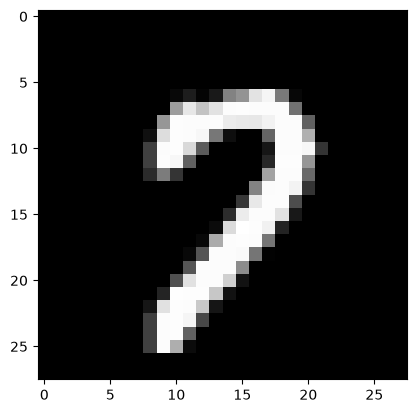

In [8]:
idx = random.randint(1, len(x_test))
image = x_test[idx]
plt.imshow(image, cmap = 'gray')
plt.show()

In [9]:
image = image.reshape(1, image.shape[0], image.shape[1], image.shape[2])
pred = model.predict([image])
print('Predicted class is = {}'.format(np.argmax(pred)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted class is = 7


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=('Tensor(shape=(1, 28, 28, 1))',)
  warnings.warn(msg)


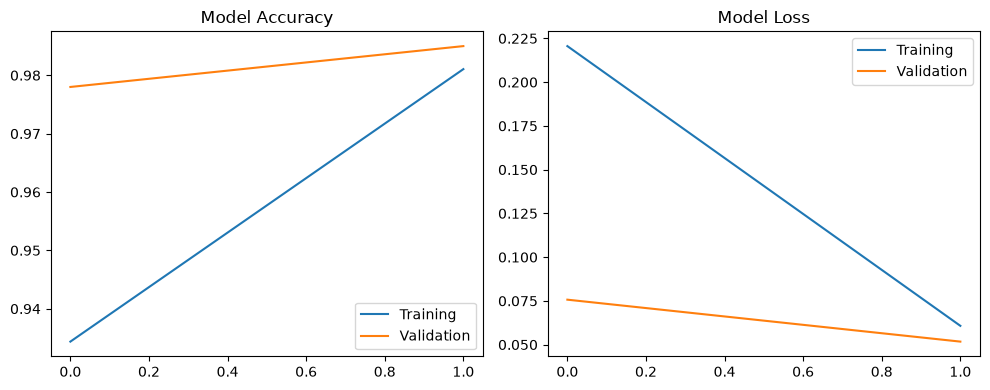

In [10]:
# loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

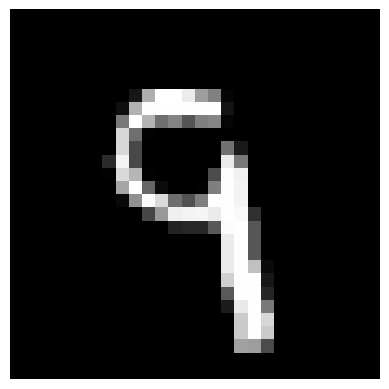

The handwritten number in the image is 9


In [15]:
import random

num = random.randrange(len(x_test))

plt.imshow(x_test[num], cmap='gray')
plt.axis('off')
plt.show()

prediction = model.predict(x_test[num:num + 1], verbose=0)

predicted_digit = int(np.argmax(prediction[0]))

print('The handwritten number in the image is', predicted_digit)